In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = {
    "Student": [
        "Amit", "Priya", "Rahul", "Sneha", "Rohan",
        "Neha", "Arjun", "Pooja", "Karan", "Anjali",
        "Vikram", "Meera"
    ],
    "Attendance": [95, 82, 60, 75, 45, 90, 68, 88, 55, 78, 98, 72],
    "Marks": [92, 78, 45, 65, 30, 85, 55, 72, 40, 60, 96, 50],
    "Assignments_Completed": [10, 9, 5, 7, 3, 10, 6, 8, 4, 7, 10, 5]
}

df = pd.DataFrame(data)

display(df)

,Student,Attendance,Marks,Assignments_Completed
0,Amit,95,92,10
1,Priya,82,78,9
2,Rahul,60,45,5
3,Sneha,75,65,7
4,Rohan,45,30,3
5,Neha,90,85,10
6,Arjun,68,55,6
7,Pooja,88,72,8
8,Karan,55,40,4
9,Anjali,78,60,7


In [3]:
def classify_student(row):

    if row["Attendance"] < 50 or row["Marks"] < 35:
        return "At Risk"

    elif (
        row["Attendance"] >= 90
        and row["Marks"] >= 85
        and row["Assignments_Completed"] == 10
    ):
        return "Excellent"

    elif (
        row["Attendance"] >= 75
        and row["Marks"] >= 60
        and row["Assignments_Completed"] >= 7
    ):
        return "Good"

    else:
        return "Needs Improvement"


df["Performance"] = df.apply(classify_student, axis=1)

display(df)

,Student,Attendance,Marks,Assignments_Completed,Performance
0,Amit,95,92,10,Excellent
1,Priya,82,78,9,Good
2,Rahul,60,45,5,Needs Improvement
3,Sneha,75,65,7,Good
4,Rohan,45,30,3,At Risk
5,Neha,90,85,10,Excellent
6,Arjun,68,55,6,Needs Improvement
7,Pooja,88,72,8,Good
8,Karan,55,40,4,Needs Improvement
9,Anjali,78,60,7,Good


In [4]:
print("Student Performance Classification\n")

for _, row in df.iterrows():
    print(
        f"Student: {row['Student']:<8} | "
        f"Attendance: {row['Attendance']:>3}% | "
        f"Marks: {row['Marks']:>3} | "
        f"Assignments: {row['Assignments_Completed']:>2}/10 | "
        f"Result: {row['Performance']}"
    )

Student Performance Classification

Student: Amit     | Attendance:  95% | Marks:  92 | Assignments: 10/10 | Result: Excellent
Student: Priya    | Attendance:  82% | Marks:  78 | Assignments:  9/10 | Result: Good
Student: Rahul    | Attendance:  60% | Marks:  45 | Assignments:  5/10 | Result: Needs Improvement
Student: Sneha    | Attendance:  75% | Marks:  65 | Assignments:  7/10 | Result: Good
Student: Rohan    | Attendance:  45% | Marks:  30 | Assignments:  3/10 | Result: At Risk
Student: Neha     | Attendance:  90% | Marks:  85 | Assignments: 10/10 | Result: Excellent
Student: Arjun    | Attendance:  68% | Marks:  55 | Assignments:  6/10 | Result: Needs Improvement
Student: Pooja    | Attendance:  88% | Marks:  72 | Assignments:  8/10 | Result: Good
Student: Karan    | Attendance:  55% | Marks:  40 | Assignments:  4/10 | Result: Needs Improvement
Student: Anjali   | Attendance:  78% | Marks:  60 | Assignments:  7/10 | Result: Good
Student: Vikram   | Attendance:  98% | Marks:  96 | 

Performance
Good                 4
Needs Improvement    4
Excellent            3
At Risk              1
Name: count, dtype: int64


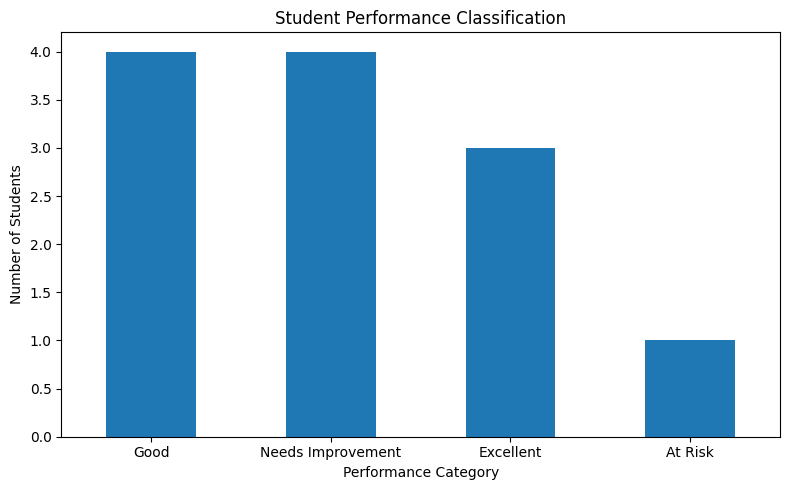

In [5]:
performance_counts = df["Performance"].value_counts()

print(performance_counts)

performance_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Student Performance Classification"
)

plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

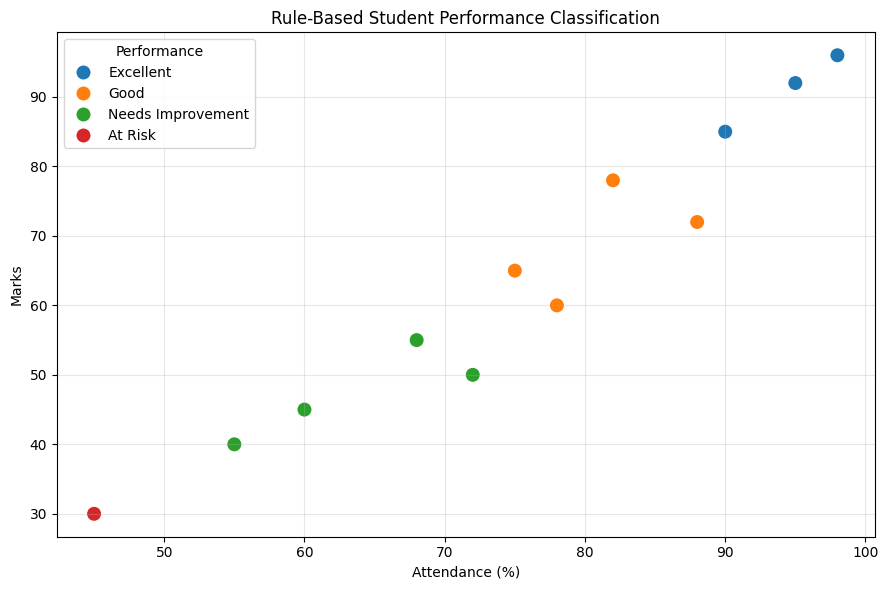

In [6]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="Marks",
    hue="Performance",
    s=120
)

plt.title("Rule-Based Student Performance Classification")
plt.xlabel("Attendance (%)")
plt.ylabel("Marks")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
new_student = pd.DataFrame([{
    "Student": "New Student",
    "Attendance": 85,
    "Marks": 80,
    "Assignments_Completed": 8
}])

new_student["Performance"] = new_student.apply(
    classify_student, axis=1
)

print("Predicted category:", new_student.loc[0, "Performance"])

Predicted category: Good


In [8]:
df.to_csv("student_classification_results.csv", index=False)

print("Results saved successfully!")

Results saved successfully!
